# **트랜스포머 (Transformer)**
<p align="right">15기 손영현</p>

---

## **1. 인트로**

### 1) RNN의 한계
- RNN은 이전 시점의 hidden state를 다음 시점으로 넘기면서 과거 정보를 기억함.
- 장기 의존성 문제: 문장이 길어지면 앞쪽 정보가 뒤까지 잘 전달되지 않음.
    - BPTT 과정에서 가중치가 계속 곱해지면서 <mark style="background-color:#CFEFFF; color:#000000">기울기 소실</mark>이 생기기 때문
- LSTM은 Cell state와 게이트(Input, Forget, Output)로 이 문제를 완화했지만, 문장이 아주 길면 여전히 기울기 소실이 생김.
- 결국 RNN, LSTM 둘 다 <mark style="background-color:#CFEFFF; color:#000000">단어를 순서대로 하나씩 처리</mark>해야 해서 병렬 처리가 안 됨.

(1) Seq2Seq 복습
- 입력 시퀀스를 다른 시퀀스로 바꾸는 모델 (번역, 요약 등)
- 인코더가 입력 문장을 순서대로 읽고 하나의 Context Vector로 압축함.
- 디코더는 이 Context Vector를 받아서 `<sos>`부터 `<eos>`까지 한 단어씩 출력함.

(2) Seq2Seq의 한계 (병목 현상)
- Context Vector 크기가 고정이라 문장이 길어질수록 <mark style="background-color:#CFEFFF; color:#000000">정보 손실</mark>이 생김.
- 디코더가 어떤 단어를 만들든 똑같은 Context Vector 하나만 참고함.
- 마지막 hidden state를 쓰기 때문에 앞쪽 단어 정보는 흐려짐.

### 2) Attention의 등장
- 개념: 출력 단어를 만들 때 입력 단어들 중 <mark style="background-color:#CFEFFF; color:#000000">지금 중요한 단어에 더 높은 가중치</mark>를 주는 방법
- 인코더의 hidden state를 전부 남겨두고, 디코더가 단어를 만들 때마다 이걸 다시 보고 새 Context Vector를 만듦.

[흐름]
1. 디코더의 현재 상태와 인코더의 각 hidden state를 비교해서 관련도 점수 계산
2. Softmax로 점수를 합이 1인 비율(Attention Weight)로 바꿈
3. 이 비율만큼 hidden state를 섞어서 Context Vector 생성

- 장점
    - 거리와 상관없이 단어 사이 관계를 바로 볼 수 있음 (RNN의 장기 의존성 문제 해결)
    - 각 단어의 점수 계산이 서로 독립적이라 동시에 계산 가능함.
- 다만 인코더, 디코더가 아직 LSTM이라서 모델 전체가 병렬화되지는 않음. -> Attention은 RNN을 도와주는 역할에 그침.

### 3) Attention is All You Need
- 2017년 Google 연구진이 발표한 논문으로, <mark style="background-color:#CFEFFF; color:#000000">Transformer를 처음 제안</mark>함.
- RNN과 CNN을 아예 빼고 Attention만으로 모델을 만들었음.
- 순서대로 처리할 필요가 없어져서 병렬화가 가능해졌고 학습 속도도 빨라짐.
- 이후 GPT(디코더 기반), BERT(인코더 기반) 같은 모델이 나오면서 지금 LLM의 기반이 됨.

(1) 트랜스포머란?
- 개념: 단어를 순서대로 처리하지 않고 <mark style="background-color:#CFEFFF; color:#000000">Attention만으로 문장 전체를 한 번에 처리</mark>하는 인코더-디코더 모델
- 구조: 인코더(입력 문장 이해) + 디코더(출력 문장 생성), 각각 같은 층을 N개 쌓아서 만듦.

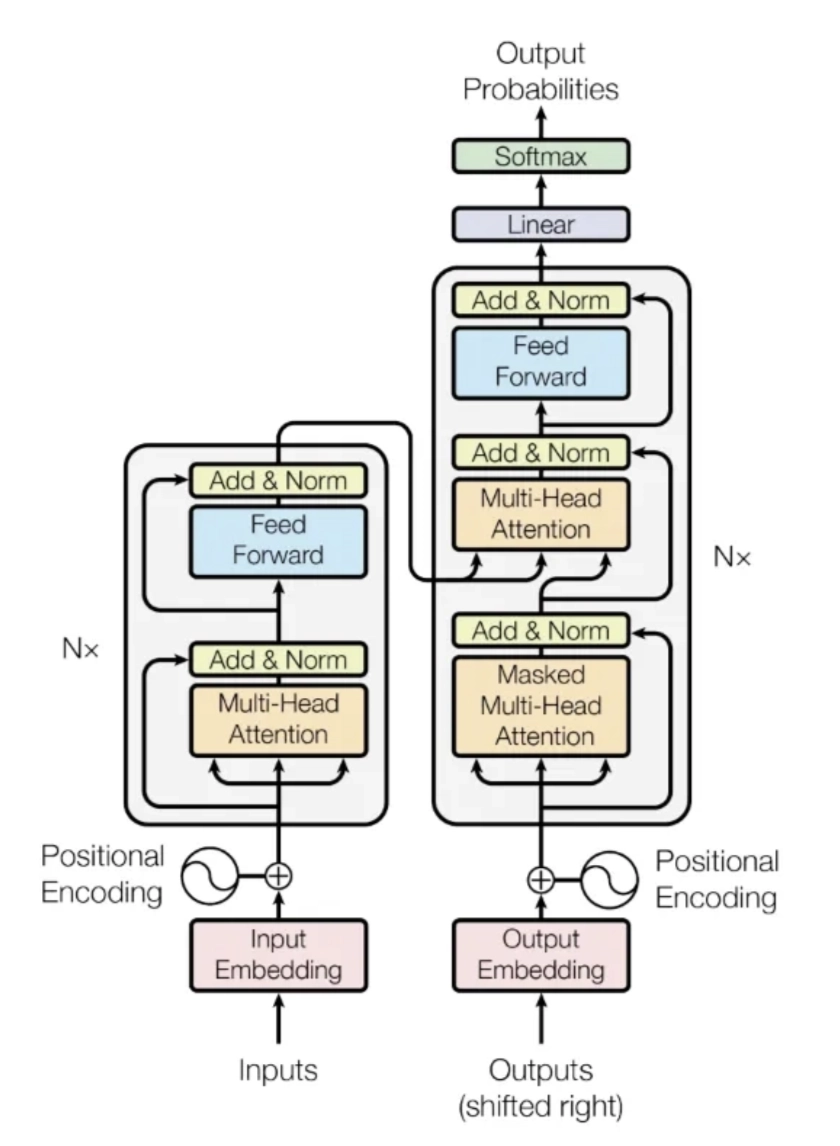

- 기존 Seq2Seq + Attention과 비교하면
    - 인코더, 디코더 안이 LSTM이 아니라 Self-Attention으로 되어 있음.
    - Attention을 인코더 안, 디코더 안, 인코더-디코더 사이 3곳에서 씀.
    - 단어 순서는 Positional Encoding으로 따로 넣어줌.
- 핵심 기술: Self-Attention, Multi-Head Attention, Positional Encoding

## **2. Self-Attention**

### 1) Query, Key, Value
- Attention은 <mark style="background-color:#CFEFFF; color:#000000">Query와 Key를 비교해서 관련도를 구하고, 그 비율만큼 Value를 섞는</mark> 계산임.
- Query(Q): 현재 단어가 다른 단어들한테 "나한테 필요한 정보가 뭐지?" 하고 묻는 벡터
- Key(K): 각 단어가 "나는 이런 정보를 갖고 있어" 하고 보여주는 벡터, Query랑 비교해서 점수를 정함.
- Value(V): 각 단어가 실제로 넘겨주는 정보
- Key와 Value를 나누는 이유: 관련 있는지 판단할 때 쓰는 정보와 실제로 전달할 정보가 다를 수 있어서

### 2) Cross-Attention vs. Self-Attention
- 공통 흐름: 입력에 $W^Q, W^K, W^V$를 곱해서 Q, K, V를 만들고 -> Q와 K로 점수 계산 -> Softmax -> V와 곱함.

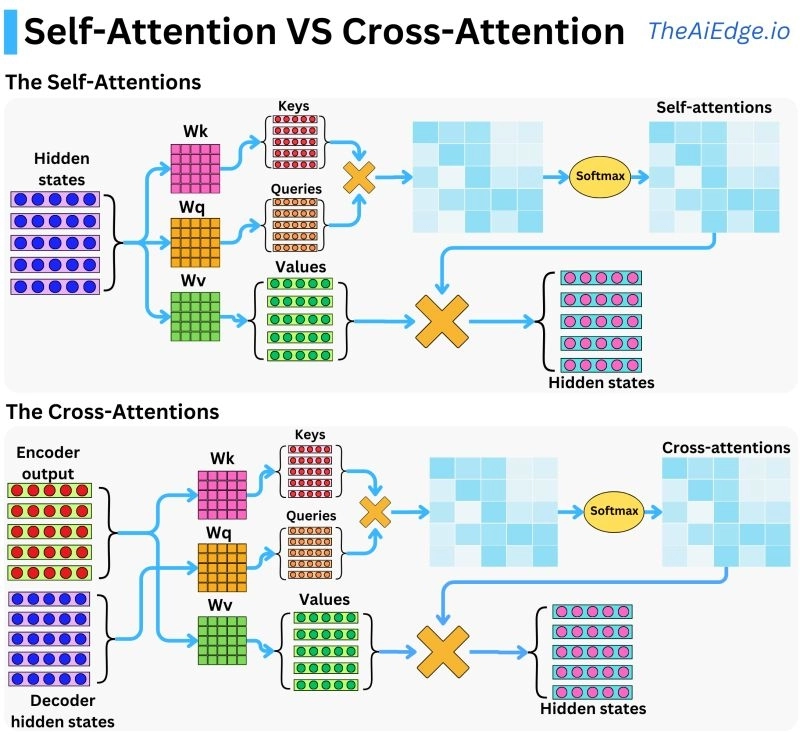

(1) Cross-Attention
- Query와 Key, Value가 <mark style="background-color:#CFEFFF; color:#000000">서로 다른 문장</mark>에서 나옴. (Q는 디코더, K와 V는 인코더)
- 기존 Seq2Seq의 Attention이 여기에 해당함.
- 예) "The cat is sleeping"을 번역하다가 "고양이가 ___" 다음 단어를 만들 때 sleeping을 가장 많이 참고함.

(2) Self-Attention
- Query와 Key, Value가 <mark style="background-color:#CFEFFF; color:#000000">같은 문장</mark>에서 나옴.
- 문장 안 단어들끼리 서로 관련도를 계산해서 문맥을 파악함. RNN 없이도 가능
- 예) "가을 은행 냄새 지독해"에서 '은행'이 '냄새', '가을'을 많이 참고해서 열매라는 의미로 업데이트됨.
- 모든 단어가 이 계산을 동시에 할 수 있어서 병렬 처리가 가능함.

- Transformer에서는 둘 다 사용함.
    - 인코더: Self-Attention
    - 디코더: Masked Self-Attention (아직 안 만든 뒤쪽 단어는 못 보게 가림)
    - 인코더-디코더 사이: Cross-Attention

### 3) Scaled Dot-Product Attention
(1) Dot-Product Attention
- Query와 Key를 <mark style="background-color:#CFEFFF; color:#000000">내적</mark>해서 관련도 점수를 구하는 방법 (두 벡터 방향이 비슷할수록 값이 큼)

$$Q \cdot K = \sum_{i=1}^{d_k} Q_iK_i$$

[과정]

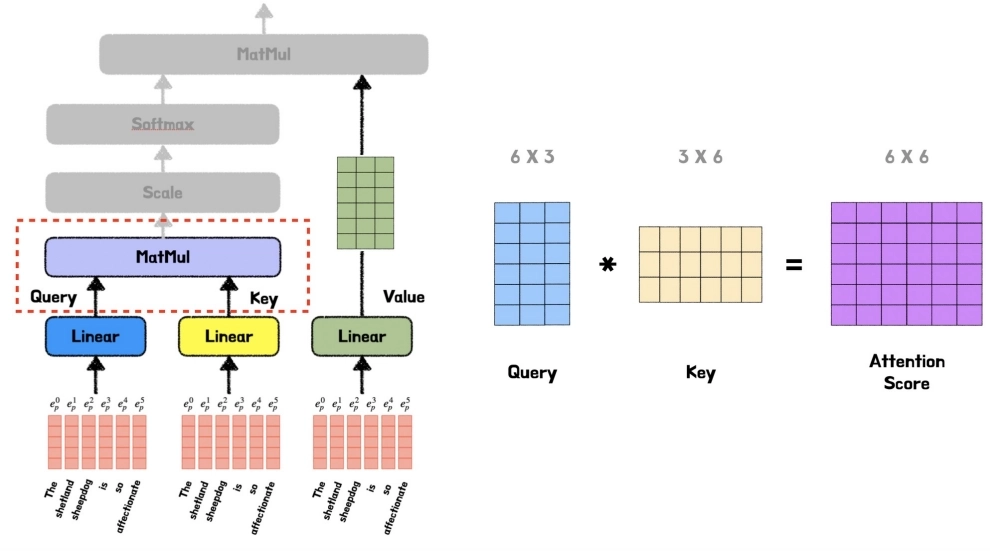

1. Q(6x3)와 전치한 K(3x6)를 곱하면 6x6 점수표가 나옴. 행렬 곱 한 번으로 모든 단어 쌍의 점수를 구할 수 있음.
2. 각 행에 Softmax를 적용해서 Attention Weight를 구함.
3. Attention Weight와 V를 곱해서 새로운 단어 벡터를 만듦.

- 문제점: 차원이 커지면 내적 값도 너무 커져서 Softmax 결과가 한 단어에 몰림 -> 기울기 소실

(2) Scaled Dot-Product Attention
- 내적한 다음 Softmax 전에 <mark style="background-color:#CFEFFF; color:#000000">$\sqrt{d_k}$로 나눠주는 스케일링</mark>을 추가한 방법
- 이렇게 하면 차원이 커져도 점수가 적당한 범위로 유지됨.

$$Attention(Q,K,V)=softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

## **3. Multi-Head Attention**

### 1) Single-Head Attention vs. Multi-Head Attention
- 헤드: 자기만의 $W^Q, W^K, W^V$를 가지고 Attention을 한 번 계산하는 단위

(1) Single-Head Attention
- 512차원 벡터로 Attention을 한 번만 계산함.
- Softmax 가중치 합이 1이라서, 한 단어가 여러 관계를 동시에 봐야 할 때 <mark style="background-color:#CFEFFF; color:#000000">가중치가 분산되어 정보가 흐려짐</mark>.
- 예) "Tom gave Mary a book yesterday"에서 gave가 Tom, Mary, book, yesterday에 비슷하게 나눠서 집중함.

(2) Multi-Head Attention
- Attention을 <mark style="background-color:#CFEFFF; color:#000000">여러 개로 나눠서 동시에</mark> 계산하는 방법
- 헤드마다 다른 관계에 집중할 수 있음. (누가, 누구에게, 무엇을, 언제 등)
- 각 헤드 결과를 이어 붙이니까 정보가 섞이지 않고 남음.

### 2) Multi-Head Attention 작동 방식
- 논문 기준: 단어 차원 512, 헤드 8개, 헤드당 64차원

1. 분할: 헤드마다 다른 가중치를 곱해서 64차원 Q, K, V를 8세트 만듦.
2. 병렬 계산: 8개 헤드가 각자 Scaled Dot-Product Attention을 계산함. ($\sqrt{64}=8$로 나눔)
3. Concat: 8개의 64차원 결과를 이어 붙여서 512차원으로 만듦.
4. 최종 투영: <mark style="background-color:#CFEFFF; color:#000000">$W^O$를 곱해서 헤드들의 결과를 하나로 합침</mark>.

- 예) "I love you"에서 love의 헤드 1 가중치가 I 0.2, love 0.7, you 0.1이라면, 이 비율로 V를 섞은 게 헤드 1의 결과가 됨.

## **4. Transformer 전체 아키텍처**

### 1) 트랜스포머의 전처리 단계
[흐름] 입력 -> 토큰화 -> 임베딩 -> Positional Encoding

(1) 토큰화
- 문장을 모델이 다루는 <mark style="background-color:#CFEFFF; color:#000000">기본 단위(토큰)</mark>로 자르는 것
- 보통 단어 하나가 토큰 하나고, 문장 부호도 토큰임. 길거나 드문 단어는 여러 조각으로 나눔. (didn't -> did + n't)

(2) 임베딩
- 토큰을 <mark style="background-color:#CFEFFF; color:#000000">숫자 벡터</mark>로 바꾸는 것, 벡터 길이가 곧 차원($d_{model}$)
- 뜻이 비슷한 단어끼리 가까운 위치에 놓이도록 학습됨. (딸기와 체리는 가깝고, 성은 멂)
- 처음엔 랜덤 값이고 학습하면서 의미에 맞게 바뀜.

(3) Positional Encoding
- 단어의 <mark style="background-color:#CFEFFF; color:#000000">순서 정보</mark>를 임베딩 벡터에 더해주는 것
- Transformer는 단어를 한꺼번에 보기 때문에 따로 순서를 알려주지 않으면 "개는 고양이를 쫓는다"와 "고양이는 개를 쫓는다"를 구분 못 함.
- 위치마다 정해진 벡터를 임베딩에 더함. (이어 붙이는 게 아니라 더하는 것)

### 2) Encoder와 Decoder

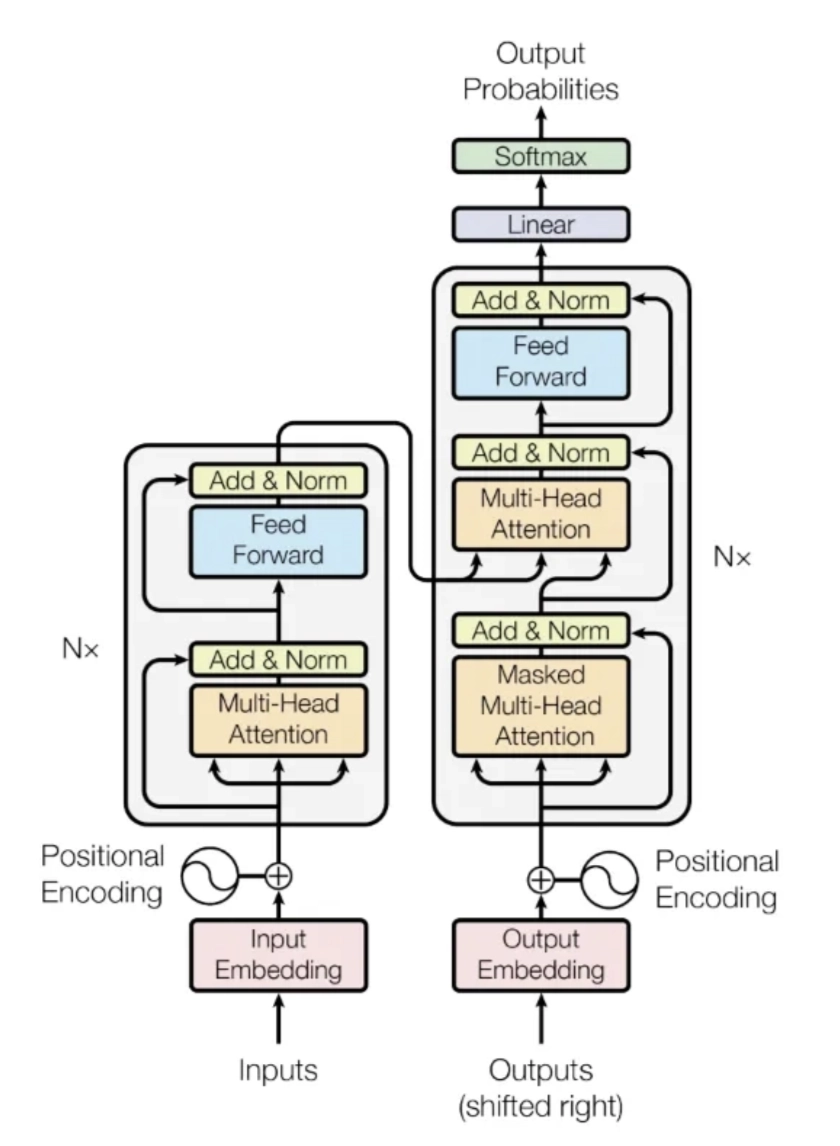

(1) Encoder
- <mark style="background-color:#CFEFFF; color:#000000">Multi-Head Self-Attention + Feed-Forward Network</mark>로 된 층을 6개 쌓음.
- Self-Attention으로 원문 단어끼리 문맥을 파악하고, FFN으로 단어마다 따로 한 번 더 가공함.
- FFN: 512 -> 2048 -> 512로 늘렸다가 줄이는 2층 신경망 (중간에 ReLU), 모든 단어에 같은 가중치를 씀.

$$FFN(x) = \max(0,\ xW_1 + b_1)W_2 + b_2$$

- 출력: RNN은 마지막 hidden state 하나만 넘기지만, Transformer 인코더는 단어별 벡터를 전부 넘김.

- Add & Norm: 각 부품 뒤에 붙음.
    - Add(잔차 연결): 부품을 통과한 결과에 원래 입력을 더함. (ResNet에서 나온 아이디어)
    - Norm(층 정규화): 벡터 값들을 평균 0, 분산 1 근처로 맞춰서 학습을 안정적으로 만듦.

(2) Decoder
- 층 하나가 3개 부품으로 되어 있고 각각 뒤에 Add & Norm이 붙음. 6층을 지나면 Linear + Softmax로 다음 단어 확률을 구함.
    1. Masked Multi-Head Self-Attention
    2. Encoder-Decoder Attention (Cross-Attention)
    3. Feed-Forward Network

- Masked Multi-Head Attention
    - <mark style="background-color:#CFEFFF; color:#000000">뒤에 나올 단어를 가리고</mark> 앞 단어들만 보게 하는 것
    - 학습할 때 정답 문장을 한 번에 넣기 때문에, 안 가리면 정답을 미리 보고 맞히는 셈이 됨.
    - 예) "I go to" 다음 단어를 예측할 때 "school"을 보면 안 됨.

- Encoder-Decoder Attention
    - Q는 디코더 쪽에서, <mark style="background-color:#CFEFFF; color:#000000">K와 V는 인코더 마지막 층 출력</mark>에서 가져옴.
    - 번역할 때 원문에서 어디를 봐야 하는지 찾는 역할
    - 예) "school"을 만들 차례면 원문의 "학교"에 높은 가중치가 감.

### 3) 전체 흐름 정리 (I love you 번역)
1. I, love, you를 임베딩하고 위치 벡터를 더함.
2. 인코더 6층을 지나면서 각 단어가 문맥이 반영된 벡터가 됨. -> 디코더의 K, V로 전달
3. 디코더가 `<start>`부터 한 단어씩 만듦.
    - `<start>` -> "나는" (I 참고)
    - "나는" -> "당신을" (you 참고)
    - "당신을" -> "사랑해" (love 참고)
    - 더 옮길 내용이 없으면 `<end>`를 출력하고 끝남.